# Negation-aware retrieval, Ru/Kz legal texts — final analysis

Reads only `results/*.json`; figures go to `results/figures/`. Test split of the reviewed question set v1
(49 pairs: dev 10, test 39 = 20 general + 19 negation per language). Seed 42, paired bootstrap 1000,
95% percentile CI.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = ROOT / "results"
FIG = RES / "figures"
FIG.mkdir(exist_ok=True)

def load(name):
    return json.loads((RES / name).read_text(encoding="utf-8"))

# light chart palette: Ru = slot 1, Kz = slot 2; text in neutral ink
RU, KZ, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "axes.axisbelow": True,
                     "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
pd.set_option("display.precision", 2)

## 1. Retrieval ladder on test (Recall@5, Negation Gap, Twin-above-Gold)

In [2]:
final = load("final_table.json")
rows = []
for k, v in final["test_table"].items():
    model, lang, run = [x.strip() for x in k.split("|")]
    rows.append({"model": model, "lang": lang, "run": run, **v})
tab = pd.DataFrame(rows)
print("selected on dev:", {m: (c["alpha"], c["b3_variant"]) for m, c in final["selected_on_dev"].items()})
tab.pivot_table(index=["model", "run"], columns="lang",
                values=["general_r5", "negation_r5", "twin_above_gold"], sort=False)

selected on dev: {'bge-m3': (0.0, 's1-lin-0.25'), 'e5-base': (0.0, 's2-rrf')}


general_r5       negation_r5        \
lang                                   ru    kz          ru    kz   
model   run                                                         
bge-m3  B0                           0.95  0.95        0.79  0.97   
        B1                           0.80  0.80        0.58  0.74   
        B2                           0.85  0.90        0.74  0.89   
        B3'-jina-v2                  0.93  0.90        0.84  0.92   
        B3'-bge-reranker-v2-m3       1.00  0.95        0.84  0.92   
        B3-rule-0                    0.85  0.90        0.74  0.89   
        B3-nli-a-s1-lin-0.25         0.90  0.90        0.74  0.89   
e5-base B0                           0.93  0.78        0.74  0.47   
        B1                           0.72  0.85        0.68  0.58   
        B2                           0.82  0.90        0.68  0.68   
        B3'-jina-v2                  0.97  0.90        0.84  0.84   
        B3'-bge-reranker-v2-m3       1.00  0.95        0.89  0.89   
        B3-rule-0                    0.82  0.90        0.68  0.68   
        B3-nli-a-s2-rrf              0.88  0.85        0.79  0.63   

                               twin_above_gold        
lang                                        ru    kz  
model   run                                           
bge-m3  B0                                0.14  0.07  
        B1                                0.36  0.14  
        B2                                0.21  0.07  
        B3'-jina-v2                       0.07  0.07  
        B3'-bge-reranker-v2-m3            0.07  0.00  
        B3-rule-0                         0.21  0.07  
        B3-nli-a-s1-lin-0.25              0.36  0.07  
e5-base B0                                0.29  0.43  
        B1                                0.36  0.36  
        B2                                0.21  0.14  
        B3'-jina-v2                       0.07  0.14  
        B3'-bge-reranker-v2-m3            0.07  0.07  
        B3-rule-0                         0.21  0.14  
        B3-nli-a-s2-rrf                   0.21  0.21

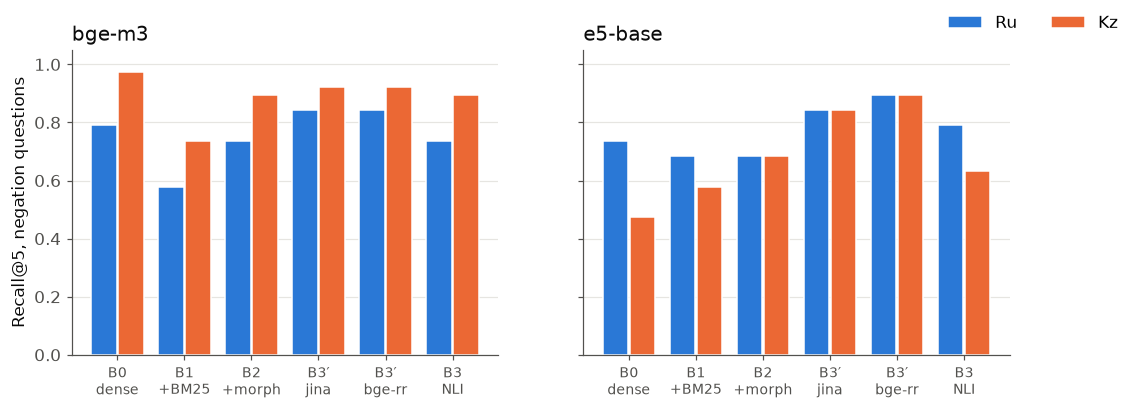

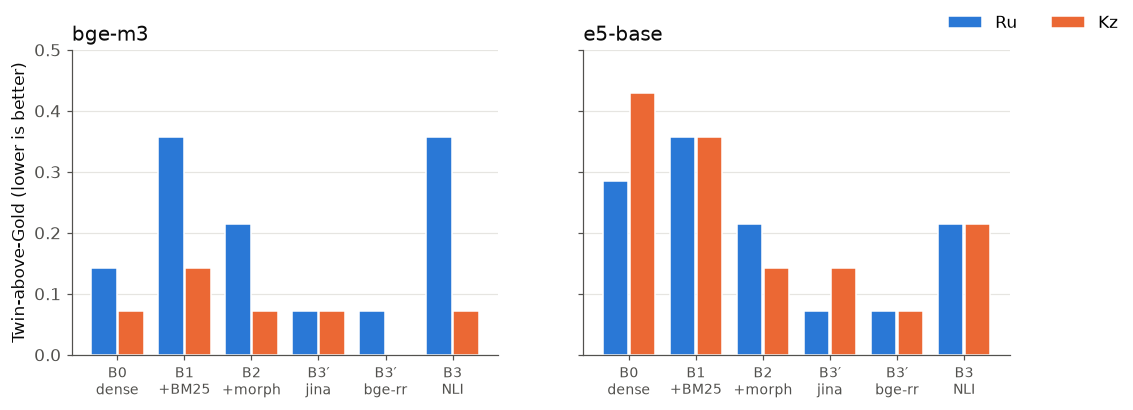

In [3]:
LADDER = ["B0", "B1", "B2", "B3'-jina-v2", "B3'-bge-reranker-v2-m3"]
LABEL = {"B0": "B0\ndense", "B1": "B1\n+BM25", "B2": "B2\n+morph", "B3'-jina-v2": "B3′\njina",
         "B3'-bge-reranker-v2-m3": "B3′\nbge-rr", "B3": "B3\nNLI"}

def ladder_runs(model):
    return LADDER + [final["selected_on_dev"][model]["B3"]]

def bars(metric, ylabel, fname, ylim):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
    for ax, model in zip(axes, ["bge-m3", "e5-base"]):
        runs = ladder_runs(model)
        x = range(len(runs))
        for off, lang, color in ((-0.2, "ru", RU), (0.2, "kz", KZ)):
            vals = [final["test_table"][f"{model} | {lang} | {r}"][metric] for r in runs]
            ax.bar([i + off for i in x], vals, width=0.38, color=color, label={"ru": "Ru", "kz": "Kz"}[lang],
                   edgecolor="white", linewidth=1)
        ax.set_xticks(list(x), [LABEL.get(r, LABEL["B3"]) for r in runs], fontsize=9)
        ax.set_title(model, color=INK, loc="left")
        ax.set_ylim(*ylim)
    axes[0].set_ylabel(ylabel)
    fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, loc="upper right", ncol=2)
    fig.savefig(FIG / fname)
    plt.show()

bars("negation_r5", "Recall@5, negation questions", "ladder_negation_r5.png", (0, 1.05))
bars("twin_above_gold", "Twin-above-Gold (lower is better)", "ladder_twin_above_gold.png", (0, 0.5))

In [4]:
tests = final["hypothesis_tests"]
out = []
for k, v in tests.items():
    for metric, r in v.items():
        d = r.get("diff", r.get("kz_minus_ru_gain"))
        out.append({"test": k, "metric": metric, "diff": d, "lo": r["ci95"][0], "hi": r["ci95"][1],
                    "CI excludes 0": r["excludes_0"]})
ht = pd.DataFrame(out)
ht[ht["CI excludes 0"]]   # the only differences that count as found

,test,metric,diff,lo,hi,CI excludes 0
6,bge-m3 | ru | H2 B3 vs B3'-bge-reranker-v2-m3,twin_above_gold/value,0.29,0.07,0.54,True
33,e5-base | kz | H1 B2 vs B0,negation/recall@5,0.21,0.05,0.42,True
34,e5-base | kz | H2 B3 vs B3'-jina-v2,negation/recall@5,-0.21,-0.42,-0.05,True
36,e5-base | kz | H2 B3 vs B3'-bge-reranker-v2-m3,negation/recall@5,-0.26,-0.47,-0.11,True
41,e5-base | H3 B2,negation,0.26,0.11,0.47,True


In [5]:
ht

,test,metric,diff,lo,hi,CI excludes 0
0,bge-m3 | ru | H1 B2 vs B0,negation_gap,-0.05,-0.25,0.16,False
1,bge-m3 | ru | H1 B2 vs B0,general/recall@5,-0.10,-0.30,0.10,False
2,bge-m3 | ru | H1 B2 vs B0,negation/recall@5,-0.05,-0.16,0.00,False
3,bge-m3 | ru | H2 B3 vs B3'-jina-v2,negation/recall@5,-0.11,-0.32,0.11,False
4,bge-m3 | ru | H2 B3 vs B3'-jina-v2,twin_above_gold/value,0.29,0.00,0.60,False
5,bge-m3 | ru | H2 B3 vs B3'-bge-reranker-v2-m3,negation/recall@5,-0.11,-0.26,0.00,False
6,bge-m3 | ru | H2 B3 vs B3'-bge-reranker-v2-m3,twin_above_gold/value,0.29,0.07,0.54,True
7,bge-m3 | ru | H2 B3 vs B3-rule-0,negation/recall@5,0.00,0.00,0.00,False
8,bge-m3 | ru | H2 B3 vs B3-rule-0,twin_above_gold/value,0.14,0.00,0.36,False
9,bge-m3 | kz | H1 B2 vs B0,negation_gap,0.03,-0.12,0.18,False


## 2. Controls (test): negation tokens in BM25, fusion weight, zero-shot NLI

In [6]:
ctl = load("controls_test.json")
names = ["B0", "B2-noneg", "B2", "B2-w0.25", "B2-w0.5", "B2-w1", "B2-w2"]
rows = []
for model in ("bge-m3", "e5-base"):
    for n in names:
        for lang in ("ru", "kz"):
            s = ctl["langs"][lang]["summary"][f"{model}/{n}"]
            rows.append({"model": model, "run": n, "lang": lang, "gen R@5": s["general"]["recall@5"],
                         "neg R@5": s["negation"]["recall@5"], "TaG": s["twin_above_gold"]["value"]})
pd.DataFrame(rows).pivot_table(index=["model", "run"], columns="lang", values=["gen R@5", "neg R@5", "TaG"], sort=False)

gen R@5       neg R@5         TaG      
lang                  ru    kz      ru    kz    ru    kz
model   run                                             
bge-m3  B0          0.95  0.95    0.79  0.97  0.14  0.07
        B2-noneg    0.85  0.90    0.74  0.89  0.21  0.07
        B2          0.85  0.90    0.74  0.89  0.21  0.07
        B2-w0.25    1.00  0.95    0.79  0.97  0.14  0.00
        B2-w0.5     1.00  0.90    0.74  0.89  0.21  0.07
        B2-w1       0.85  0.90    0.74  0.89  0.21  0.07
        B2-w2       0.80  0.90    0.68  0.84  0.29  0.07
e5-base B0          0.93  0.78    0.74  0.47  0.29  0.43
        B2-noneg    0.88  0.90    0.74  0.68  0.21  0.14
        B2          0.82  0.90    0.68  0.68  0.21  0.14
        B2-w0.25    0.93  0.90    0.74  0.58  0.29  0.43
        B2-w0.5     0.93  0.95    0.74  0.63  0.29  0.36
        B2-w1       0.82  0.90    0.68  0.68  0.21  0.14
        B2-w2       0.82  0.85    0.68  0.68  0.29  0.07

In [7]:
rows = []
for model in ("bge-m3", "e5-base"):
    for nli in ("mDeBERTa-v3-base-xnli-multilingual-nli-2mil7", "nli-a"):
        for sfx in ("", "-decl"):
            prefix = f"{model}/B3-{nli}{sfx}-"
            for lang in ("ru", "kz"):
                for k, s in ctl["langs"][lang]["summary"].items():
                    if k.startswith(prefix):
                        rows.append({"model": model, "nli": ("zero-shot" if nli != "nli-a" else "fine-tuned a") + sfx,
                                     "lang": lang, "R@5": (s["general"]["recall@5"] + s["negation"]["recall@5"]) / 2,
                                     "TaG": s["twin_above_gold"]["value"]})
nli_runs = pd.DataFrame(rows)
nli_runs.groupby(["model", "nli"])[["R@5", "TaG"]].mean()   # mean over the 10 scoring/fusion variants and 2 langs

R@5   TaG
model   nli                          
bge-m3  fine-tuned a       0.77  0.26
        fine-tuned a-decl  0.73  0.31
        zero-shot          0.75  0.25
        zero-shot-decl     0.70  0.30
e5-base fine-tuned a       0.72  0.30
        fine-tuned a-decl  0.68  0.36
        zero-shot          0.70  0.27
        zero-shot-decl     0.66  0.31

## 3. D1: Negation Margin with the size-matched control

In [8]:
rows = []
for lang in ("ru", "kz"):
    pool = load(f"d1_pool_{lang}.json")["models"]
    for model, v in pool.items():
        rows.append({"model": model, "lang": lang,
                     "margin (vs paraphrase)": v["margin"]["mean"], "lo": v["margin"]["mean_ci95"][0],
                     "hi": v["margin"]["mean_ci95"][1], "share < 0": v["margin"]["frac_negative"],
                     "margin (vs one-word synonym)": v["margin_min"]["mean"],
                     "control share < 0": v["margin_min"]["frac_negative"]})
d1 = pd.DataFrame(rows)
d1

,model,lang,margin (vs paraphrase),lo,hi,share < 0,margin (vs one-word synonym),control share < 0
0,e5-base,ru,-1.81e-02,-0.02,-1.25e-02,0.90,1.79e-02,0.07
1,e5-large-instruct,ru,-3.52e-03,-0.01,3.41e-03,0.57,2.80e-02,0.03
2,bge-m3,ru,-8.35e-03,-0.04,1.96e-02,0.57,9.94e-02,0.03
3,labse,ru,-7.31e-02,-0.09,-5.59e-02,0.97,3.31e-02,0.00
4,qwen3-emb-0.6b,ru,-1.22e-01,-0.14,-1.02e-01,1.00,3.01e-02,0.07
5,embeddinggemma-2,ru,-6.46e-02,-0.08,-5.34e-02,1.00,5.05e-03,0.37
6,e5-base,kz,-1.35e-02,-0.02,-6.55e-03,0.80,2.53e-02,0.00
7,e5-large-instruct,kz,-1.86e-02,-0.02,-1.32e-02,0.90,1.42e-02,0.00
8,bge-m3,kz,-1.31e-02,-0.04,1.41e-02,0.63,9.70e-02,0.00
9,labse,kz,-7.18e-02,-0.09,-5.39e-02,0.90,4.35e-02,0.00


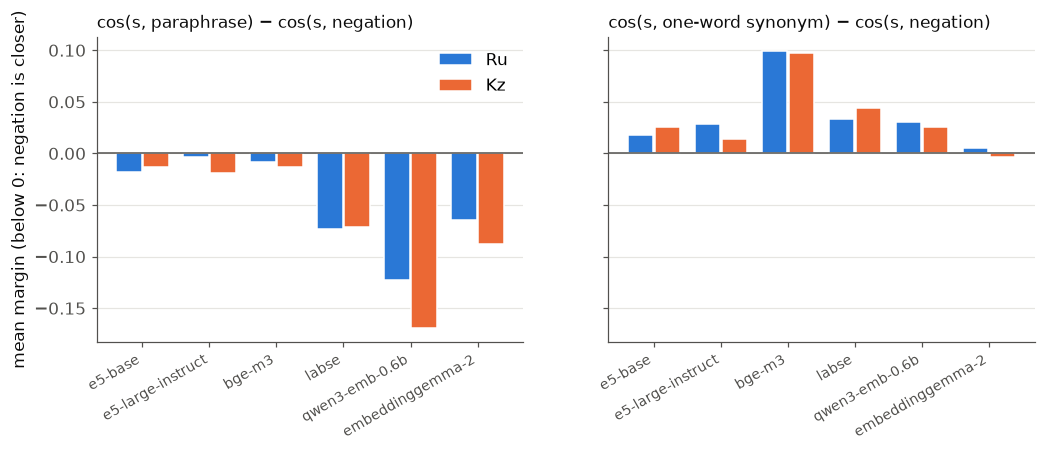

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
models = list(dict.fromkeys(d1["model"]))
for ax, (col, title) in zip(axes, [("margin (vs paraphrase)", "cos(s, paraphrase) − cos(s, negation)"),
                                   ("margin (vs one-word synonym)", "cos(s, one-word synonym) − cos(s, negation)")]):
    for off, lang, color in ((-0.2, "ru", RU), (0.2, "kz", KZ)):
        sub = d1[d1.lang == lang].set_index("model").loc[models]
        ax.bar([i + off for i in range(len(models))], sub[col], width=0.38, color=color, label=lang.capitalize(),
               edgecolor="white", linewidth=1)
    ax.axhline(0, color=INK2, linewidth=1)
    ax.set_xticks(range(len(models)), models, rotation=30, ha="right", fontsize=9)
    ax.set_title(title, color=INK, loc="left", fontsize=11)
axes[0].set_ylabel("mean margin (below 0: negation is closer)")
axes[0].legend(frameon=False)
fig.savefig(FIG / "d1_margin_with_control.png")
plt.show()

## 4. D2: Affix Isolation Rate (171 checked Kazakh negative forms)

In [10]:
d2 = load("d2_pool.json")["tokenizers"]
pd.DataFrame([{"tokenizer": k, "isolation": v["kz"]["isolation_rate"], "any boundary": v["kz"]["any_boundary_rate"],
               "freq-weighted isolation": v["kz"]["isolation_rate_freq_weighted"]} for k, v in d2.items()]
             ).sort_values("isolation", ascending=False)

,tokenizer,isolation,any boundary,freq-weighted isolation
4,mbert,0.50,0.95,0.51
3,gemma BPE,0.43,1.00,0.41
6,rubert,0.36,0.84,0.33
7,user-bge-m3 (ru-pruned),0.30,1.00,0.29
2,qwen3 byte-BPE,0.26,0.93,0.35
0,"xlm-r (e5, bge-m3, gte, arctic, jina-v3)",0.21,0.96,0.25
5,mdeberta-v3,0.12,0.77,0.19
1,labse,0.09,0.67,0.12
9,kazbert,0.05,0.63,0.04
8,kaz-roberta,0.00,0.31,0.00


## 5. NLI models: validation sets, H5 and H6

In [11]:
files = {"start (zero-shot)": "mDeBERTa-v3-base-xnli-multilingual-nli-2mil7", "a": "nli-a", "b": "nli-b",
         "c": "nli-c", "d": "nli-d"}
rows = []
for label, tag in files.items():
    s = load(f"nli_eval_final-{tag}_2026-11-16.json")["sets"]
    rows.append({"model": label, "Kardeş kk": s["kardes-kk-report"]["accuracy"], "LiDiRus neg": s["lidirus-neg"]["accuracy"],
                 "manual ru": s["manual-ru"]["accuracy"], "manual kz": s["manual-kz"]["accuracy"],
                 "synthetic ru": s["synthetic-ru-test"]["accuracy"],
                 "synthetic ru range err": s["synthetic-ru-test"].get("range_negation_error")})
pd.DataFrame(rows).set_index("model")

,Kardeş kk,LiDiRus neg,manual ru,manual kz,synthetic ru,synthetic ru range err
model,,,,,,
start (zero-shot),0.78,0.84,0.62,0.56,0.68,0.00
a,0.81,0.83,0.56,0.48,0.97,0.01
b,0.81,0.84,0.64,0.50,0.97,0.01
c,0.80,0.84,0.40,0.40,0.65,1.00
d,0.80,0.83,0.50,0.44,0.97,0.01


In [12]:
h = load("nli_h5_h6_2026-11-16.json")["comparisons"]
pd.DataFrame([{"hyp": c["hypothesis"], "pair": f"{c['b']} vs {c['a']}", "set": c["set"], "metric": c["metric"],
               "diff": c["diff"], "lo": c["ci95"][0], "hi": c["ci95"][1], "n": c["n"], "CI excludes 0": c["excludes_0"]}
              for c in h])

,hyp,pair,set,metric,diff,lo,hi,n,CI excludes 0
0,H5,0.812 vs 0.807,kardes-kk-report,accuracy,5.00e-03,-1.00e-02,1.90e-02,1000,False
1,H5,0.9743589743589743 vs 0.9715099715099715,synthetic-ru-test,accuracy,2.85e-03,0.00e+00,8.55e-03,351,False
2,H5,0.00909090909090909 vs 0.00909090909090909,synthetic-ru-test,range_negation_error,0.00e+00,0.00e+00,0.00e+00,110,False
3,H5,0.996268656716418 vs 0.9925373134328358,synthetic-kz-test,accuracy,3.73e-03,0.00e+00,1.12e-02,268,False
4,H5,0.0 vs 0.0,synthetic-kz-test,range_negation_error,0.00e+00,0.00e+00,0.00e+00,26,False
5,H5,0.64 vs 0.56,manual-ru,accuracy,8.00e-02,2.00e-02,1.60e-01,50,True
6,H5,0.0 vs 0.0,manual-ru,range_negation_error,0.00e+00,0.00e+00,0.00e+00,9,False
7,H5,0.5 vs 0.48,manual-kz,accuracy,2.00e-02,-4.00e-02,8.05e-02,50,False
8,H5,0.1111111111111111 vs 0.1111111111111111,manual-kz,range_negation_error,0.00e+00,0.00e+00,0.00e+00,9,False
9,H5,0.801 vs 0.807,kardes-kk-report,accuracy,-6.00e-03,-2.30e-02,1.00e-02,1000,False


## 6. External checks: the pipeline reproduces published numbers

In [13]:
rows = []
for name, file in (("RuLawRetrieval tk_hard", "external_rulaw_bge-m3+e5-base_2026-11-14.json"),
                   ("KazQAD (subsample)", "external_kazqad_bge-m3+e5-base_2026-11-14.json")):
    for model, v in load(file)["results"].items():
        rows.append({"benchmark": name, "model": model, "nDCG@10": v["ndcg@10"]})
display(pd.DataFrame(rows).pivot(index="model", columns="benchmark", values="nDCG@10"))
pd.Series(load("nevir_check_2026-11-15.json")["results"], name="NevIR pairwise acc (random 0.25)")

benchmark,KazQAD (subsample),RuLawRetrieval tk_hard
model,,
bge-m3,0.61,0.84
bm25-morph,0.46,0.50
bm25-plain,0.35,0.39
e5-base,0.49,0.76


bi-encoder bge-m3                   0.27
bi-encoder e5-base                  0.19
cross-encoder jina-v2               0.65
cross-encoder bge-reranker-v2-m3    0.43
NLI mdeberta-xnli (start) s1        0.57
NLI mdeberta-xnli (start) s2        0.34
NLI nli-a (tuned) s1                0.56
NLI nli-a (tuned) s2                0.20
Name: NevIR pairwise acc (random 0.25), dtype: float64

## 7. Error analysis (20 test misses)

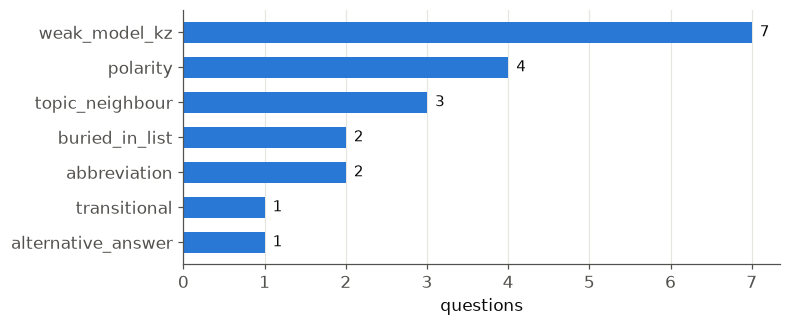

,qid,slice,rank_gold,rank_twin,tag,category,note
0,ru_tax_001,negation,99,5.0,twin_on_top,polarity,Twin 383:1 («доход возникает при продаже жилья...
1,ru_tax_004,negation,27,NaN,other_code,buried_in_list,Алименты — подпункт 13 в списке из 283 слов (4...
2,ru_tax_009,negation,8,92.0,same_code,topic_neighbour,Top-1/2 — определения облагаемого и необлагаем...
3,kz_tax_009,negation,11,4.0,twin_on_top,polarity,"Twin 480:1 (НДС, относимый в зачёт) на 4-м мес..."
4,kz_tax_025,general,22,NaN,same_code,topic_neighbour,Вопрос «какие доходы облагаются»; top-3 — стат...
5,ru_tax_006,negation,14,226.0,same_code,polarity,Top-1 — 258:3 «вычету подлежат неустойки (штра...
6,kz_tax_004,negation,27,NaN,other_code,buried_in_list,"То же, что ru_tax_004: алименты в длинном пере..."
7,ru_tax_014,general,6,NaN,same_code,alternative_answer,Top-1..3 — статья 394 о доходе частной практик...
8,kz_lab_001,negation,1096,32.0,same_code,weak_model_kz,"e5-base B0, gold на 1096-м: совпадение только ..."
9,kz_lab_002,negation,70,48.0,same_code,weak_model_kz,"e5-base B0, gold 70-й, twin 48-й; top — соседн..."


In [14]:
err = load("error_analysis.json")
cats = pd.Series(err["categories"]).sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(cats.index, cats.values, color=RU, height=0.6)
ax.grid(axis="x", color=GRID); ax.grid(axis="y", visible=False)
for i, v in enumerate(cats.values):
    ax.text(v + 0.1, i, str(v), va="center", color=INK, fontsize=10)
ax.set_xlabel("questions")
fig.savefig(FIG / "error_categories.png")
plt.show()
pd.DataFrame(err["cases"])[["qid", "slice", "rank_gold", "rank_twin", "tag", "category", "note"]]